### Forecast data

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import solarpy
import pvlib
import pandas as pd

In [28]:
from pathlib import Path
import sys

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

from scripts.functions import get_dmi_ghi, resample_dmi_ghi_hourly, get_forecast_data 

In [29]:
#Get raw DMI measurements 
dmi_data = get_dmi_ghi(start="2026-11-09", end="2026-11-11")

#Resample to hourly measurements
hourly_dmi = resample_dmi_ghi_hourly(dmi_data)

#Get forecasts and match with measurements
forecast_data = get_forecast_data(hourly_dmi, start="2026-11-09", end="2026-11-11")

In [30]:
dmi_data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 281 entries, 2026-11-09 00:00:00+00:00 to 2026-11-11 00:00:00+00:00
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   ghi     281 non-null    float64
dtypes: float64(1)
memory usage: 4.4 KB


In [31]:
forecast_data.keys()

dict_keys(['dmi_harmonie_arome_europe', 'metno_nordic', 'ecmwf_ifs025', 'ecmwf_aifs025_single', 'gfs_global', 'ecmwf_ifs', 'dmi_seamless', 'gfs_seamless'])

## Filter night away using solpos

Find solar position, in order to filter night data points away

In [32]:
#Calculate solar position for forecast valid times
timestamps = pd.DatetimeIndex(pd.concat(forecast_data.values())["valid_time"].unique())

solpos = pvlib.solarposition.get_solarposition(
    timestamps,
    latitude=56.93,
    longitude=8.6412,
    method="nrel_numpy",
)

solar_elevation = solpos["apparent_elevation"]

#Only keeping the daylight hours
daylight_times = timestamps[solar_elevation.to_numpy() > 0]

df_forecast_day = {
    model: df[df["valid_time"].isin(daylight_times)].copy()
    for model, df in forecast_data.items()
}

It is easiest to work with one forecast model at a time. To avoid having the rows be specified by a multi-index, we can use ``.unstack()`` function for alle forecast models, such that the index becomes just the time and the lead time become the columns. And the resulting dataframes are stored in a dictionary for each model and can be plotted.

In [33]:
#Unstacking all forecast models
forecast_unstacked = {
    model: df.set_index(["valid_time", "lead_time_h"])["ghi_forecast"].unstack()
    for model, df in df_forecast_day.items()
}

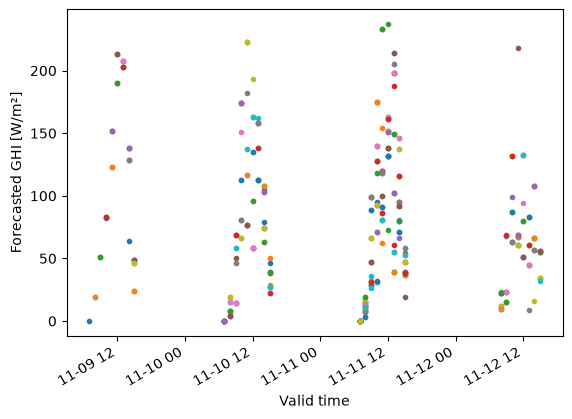

In [37]:
fig, ax = plt.subplots()
forecast_unstacked["dmi_harmonie_arome_europe"].plot(ax=ax, lw=0, marker=".")
ax.set_xlabel("Valid time")
ax.set_ylabel("Forecasted GHI [W/m²]")
ax.legend().remove()
plt.show()

$\text{\textcolor{red}{denne celle nedenfor kan slettes nu, da alle modeller er unstacket samlet ovenfor.}}$

In [ ]:
metno_nordic = df_forecast_day["metno_nordic"].unstack()
ecmwf_ifs025 = df_forecast_day["ecmwf_ifs025"].unstack()
ecmwf_aifs025_single = df_forecast_day["ecmwf_aifs025_single"].unstack()
gfs_global = df_forecast_day["gfs_global"].unstack()
ecmwf_ifs = df_forecast_day["ecmwf_ifs"].unstack()
dmi_seamless = df_forecast_day["dmi_seamless"].unstack()
gfs_seamless = df_forecast_day["gfs_seamless"].unstack()

We can add an overview of the data for each model, to help identify differences in forecast horizons and available data. 

In [38]:
for model, df in forecast_data.items():
    print(
        model,
        "| Forecasts:", len(df),
        "| Matched measurements:", df["ghi_measured"].notna().sum(),
        "| Max horizon:", df["lead_time_h"].max()
    )

dmi_harmonie_arome_europe | Forecasts: 1273 | Matched measurements: 478 | Max horizon: 56.0
metno_nordic | Forecasts: 1307 | Matched measurements: 478 | Max horizon: 57.0
ecmwf_ifs025 | Forecasts: 3529 | Matched measurements: 478 | Max horizon: 167.0
ecmwf_aifs025_single | Forecasts: 3529 | Matched measurements: 478 | Max horizon: 167.0
gfs_global | Forecasts: 3529 | Matched measurements: 478 | Max horizon: 167.0
ecmwf_ifs | Forecasts: 3529 | Matched measurements: 478 | Max horizon: 167.0
dmi_seamless | Forecasts: 3529 | Matched measurements: 478 | Max horizon: 167.0
gfs_seamless | Forecasts: 3529 | Matched measurements: 478 | Max horizon: 167.0
